# 01 - Exploratory analysis: household credit default and macro drivers

**Question for the credit/treasury team:** where is the household default rate heading over the next 6-12 months,
and which macro variables move ahead of it?

Data: Banco Central do Brasil SGS API (public). Run `python scripts/download_data.py` first; it caches raw JSON in
`data/raw/` and writes the monthly panel to `data/panel.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

from bcb_forecast import plots
from bcb_forecast.data import PROJECT_ROOT, SERIES, TARGET

warnings.filterwarnings("ignore", category=FutureWarning)
plots.style()
FIG = PROJECT_ROOT / "reports" / "figures"
panel = pd.read_csv(PROJECT_ROOT / "data" / "panel.csv", index_col=0, parse_dates=True).asfreq("MS")
pd.DataFrame([{"column": c, "SGS code": s.code, "name": s.name, "unit": s.unit,
               "first": panel[c].first_valid_index().strftime("%Y-%m"),
               "last": panel[c].last_valid_index().strftime("%Y-%m"),
               "availability lag (months)": s.availability_lag} for c, s in SERIES.items()])

,column,SGS code,name,unit,first,last,availability lag (months)
0,default_rate_hh,21084,Credit portfolio default rate (90+ days) - Hou...,% of portfolio,2011-03,2026-08,0
1,default_rate_hh_free,21112,"Credit default rate (90+ days), non-earmarked ...",% of portfolio,2011-03,2026-08,0
2,selic_target,432,"Selic target rate set by Copom (daily, monthly...",% p.a.,2011-03,2026-08,0
3,ipca_mom,433,IPCA consumer price index - monthly change,% m/m,2011-03,2026-08,0
4,lending_rate_hh,20716,Average interest rate on credit - Households -...,% p.a.,2011-03,2026-08,0
5,concessions_hh,20633,Credit concessions (new loans) - Households - ...,BRL million,2011-03,2026-08,0
6,unemployment,24369,Unemployment rate - PNAD Continua (rolling qua...,%,2012-03,2026-08,0
7,ibc_br_sa,24364,IBC-Br economic activity index - seasonally ad...,index (2002=100),2011-03,2026-07,1
8,debt_to_income_hh,29037,Household debt to the financial system / 12-mo...,%,2011-03,2026-07,1


In [2]:
print(panel.shape)
panel.describe().T.round(2)

(186, 10)


,count,mean,std,min,25%,50%,75%,max
default_rate_hh,186.0,4.10,0.70,2.89,3.66,4.00,4.37,6.03
default_rate_hh_free,186.0,5.79,0.83,4.09,5.22,5.74,6.30,8.01
selic_target,186.0,10.10,3.73,2.00,7.14,11.00,13.70,15.00
ipca_mom,186.0,0.46,0.36,-0.68,0.24,0.43,0.66,1.62
lending_rate_hh,186.0,32.68,4.66,22.65,29.78,32.52,36.36,42.29
concessions_hh,186.0,201229.07,91741.47,86104.00,128530.75,159246.50,288098.25,407588.00
unemployment,174.0,9.55,2.86,5.10,7.00,8.65,12.10,14.90
ibc_br_sa,185.0,99.85,5.09,82.97,96.37,99.13,102.81,111.14
debt_to_income_hh,185.0,42.10,4.95,34.86,38.15,40.01,48.14,49.92
ipca_12m,186.0,5.80,2.31,1.88,4.24,5.26,6.71,12.13


## 1. The target over time

`default_rate_hh` (SGS 21084) is the share of the household credit portfolio that is 90+ days past due.
The non-earmarked ("free resources") portfolio (SGS 21112) moves the same way at a higher level, because it holds
the riskier products (credit card, overdraft, personal loans).

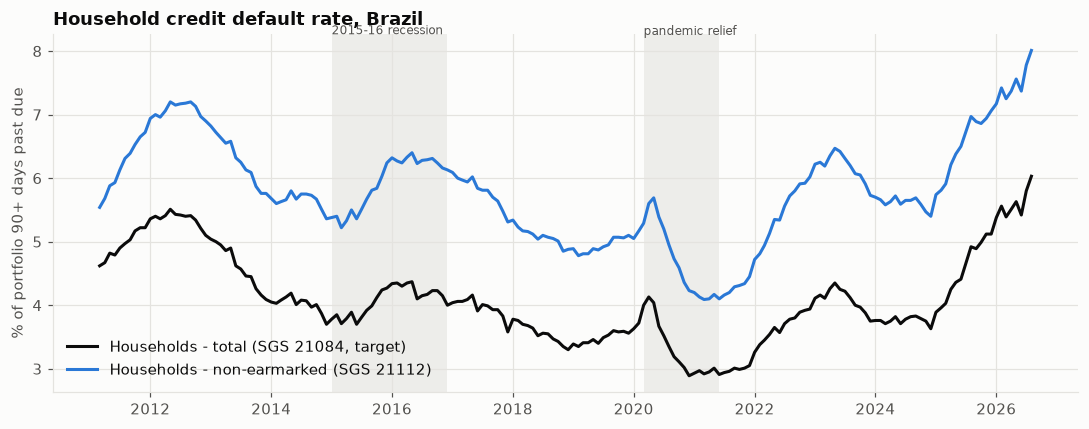

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(panel.index, panel[TARGET], color=plots.INK, label="Households - total (SGS 21084, target)")
ax.plot(panel.index, panel["default_rate_hh_free"], color=plots.MODEL_COLORS["AutoETS"],
        label="Households - non-earmarked (SGS 21112)")
ymax = panel["default_rate_hh_free"].max() * 1.05
for start, end, lbl in [("2015-01", "2016-12", "2015-16 recession"), ("2020-03", "2021-06", "pandemic relief")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=plots.GRID, alpha=0.6, lw=0)
    ax.text(pd.Timestamp(start), ymax, lbl, fontsize=8, color=plots.INK_2, va="top")
ax.set_ylabel("% of portfolio 90+ days past due")
ax.set_title("Household credit default rate, Brazil")
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "eda_target.png", dpi=110)

## 2. Trend vs. seasonality (STL decomposition)

Strength of a component = 1 - Var(remainder) / Var(component + remainder) (Hyndman & Athanasopoulos, *FPP3*).

trend strength = 0.95, seasonal strength = 0.07
average seasonal effect by calendar month (p.p.):
{1: 0.01, 2: 0.053, 3: -0.034, 4: -0.01, 5: 0.058, 6: -0.094, 7: 0.002, 8: 0.048, 9: 0.014, 10: 0.043, 11: -0.009, 12: -0.103}


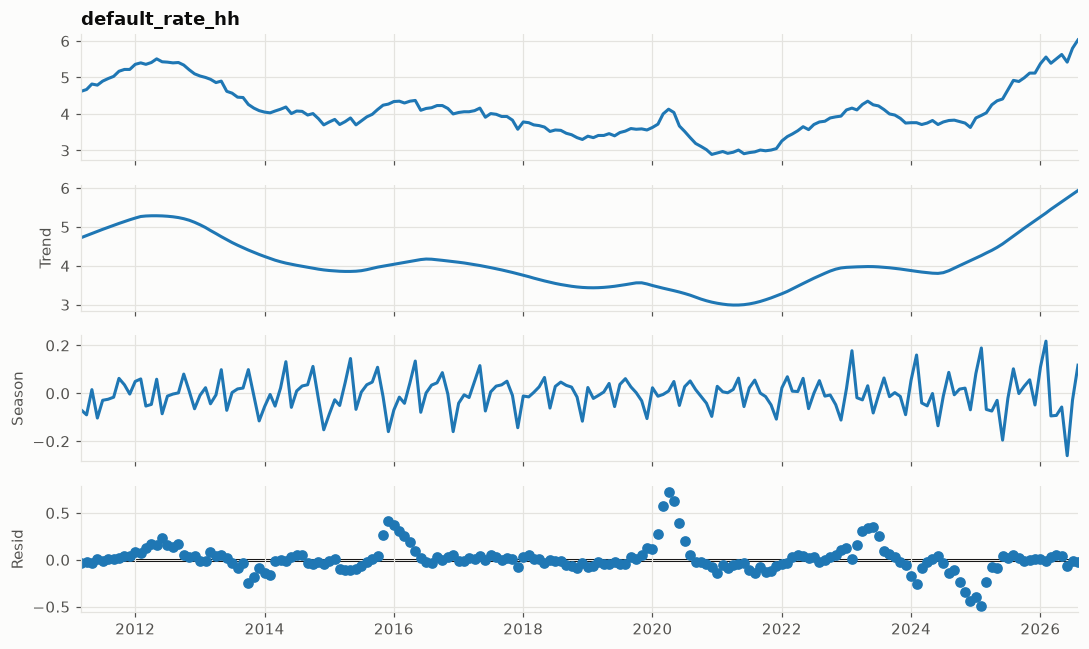

In [4]:
y = panel[TARGET]
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(10, 6); fig.tight_layout()
f_trend = 1 - stl.resid.var() / (stl.resid + stl.trend).var()
f_seas = 1 - stl.resid.var() / (stl.resid + stl.seasonal).var()
print(f"trend strength = {f_trend:.2f}, seasonal strength = {f_seas:.2f}")
print("average seasonal effect by calendar month (p.p.):")
print(stl.seasonal.groupby(stl.seasonal.index.month).mean().round(3).to_dict())

In [5]:
adf_level = adfuller(y.dropna())[1]
adf_diff = adfuller(y.diff().dropna())[1]
print(f"ADF p-value, level: {adf_level:.3f} | first difference: {adf_diff:.3f}")

ADF p-value, level: 0.396 | first difference: 0.073


## 3. Macro drivers

Small multiples (each series on its own axis: units differ).

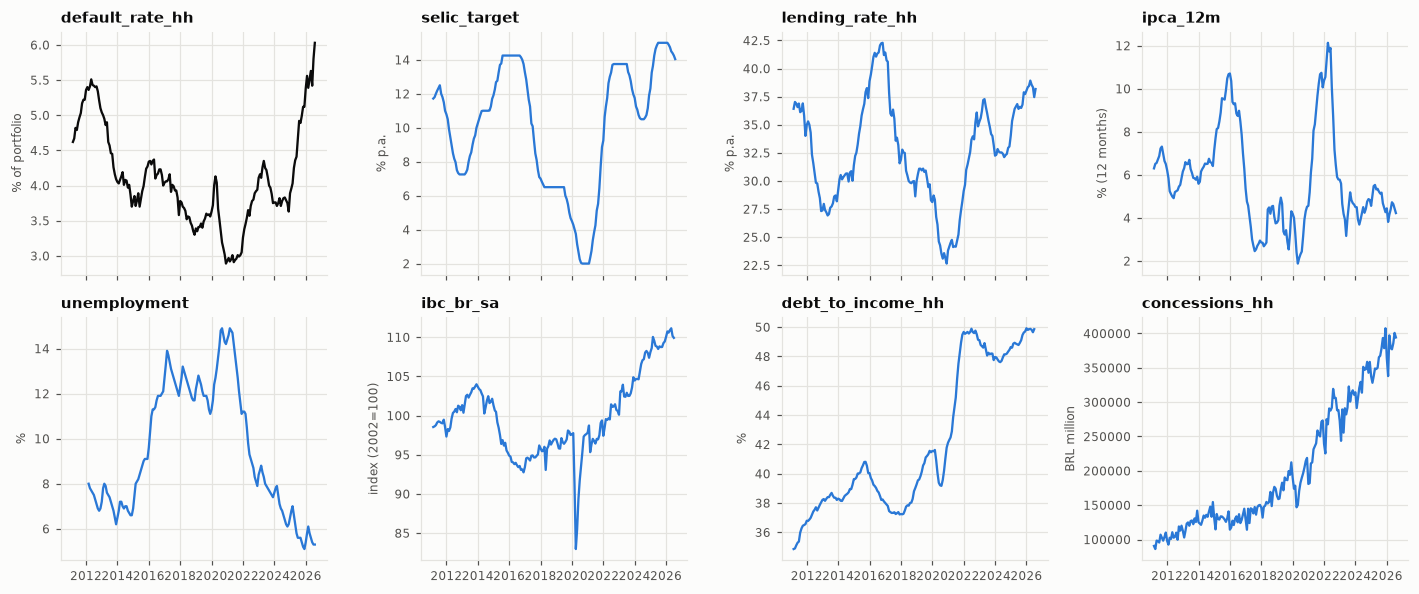

In [6]:
drivers = ["selic_target", "lending_rate_hh", "ipca_12m", "unemployment", "ibc_br_sa",
           "debt_to_income_hh", "concessions_hh"]
units = {c: SERIES[c].unit for c in drivers if c in SERIES}
units["ipca_12m"] = "% (12 months)"
units[TARGET] = SERIES[TARGET].unit
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for ax, c in zip(axes.flat, [TARGET] + drivers):
    ax.plot(panel.index, panel[c], color=plots.INK if c == TARGET else plots.MODEL_COLORS["AutoETS"], lw=1.5)
    ax.set_title(c, fontsize=10)
    ax.set_ylabel(units[c], fontsize=8)
    ax.tick_params(labelsize=8)
fig.tight_layout()

## 4. Lead-lag: which drivers move *before* default?

Correlating levels of trending series is mostly spurious, so we correlate **12-month changes**:
corr(Δ12 default[t + k], Δ12 driver[t]) for leads k = 0..18 months (log-change for concessions).
Caveat: overlapping 12-month windows make neighbouring observations highly dependent, so the effective sample is
small; read these as descriptive, not as significance tests.

In [7]:
leads = range(0, 19)
dy = y.diff(12)
cc = {}
for c in drivers:
    x = np.log(panel[c]).diff(12) if c == "concessions_hh" else panel[c].diff(12)
    cc[c] = [dy.shift(-k).corr(x) for k in leads]
cc = pd.DataFrame(cc, index=pd.Index(leads, name="lead k (months)"))
best = pd.DataFrame({"peak |corr|": cc.abs().max().round(2), "at lead k": cc.abs().idxmax(),
                     "corr at k": [round(cc.loc[cc[c].abs().idxmax(), c], 2) for c in cc]})
best.sort_values("peak |corr|", ascending=False)

,peak |corr|,at lead k,corr at k
lending_rate_hh,0.66,5,0.66
selic_target,0.65,7,0.65
ipca_12m,0.52,13,0.52
debt_to_income_hh,0.48,8,0.48
unemployment,0.44,6,-0.44
ibc_br_sa,0.31,12,0.31
concessions_hh,0.31,11,0.31


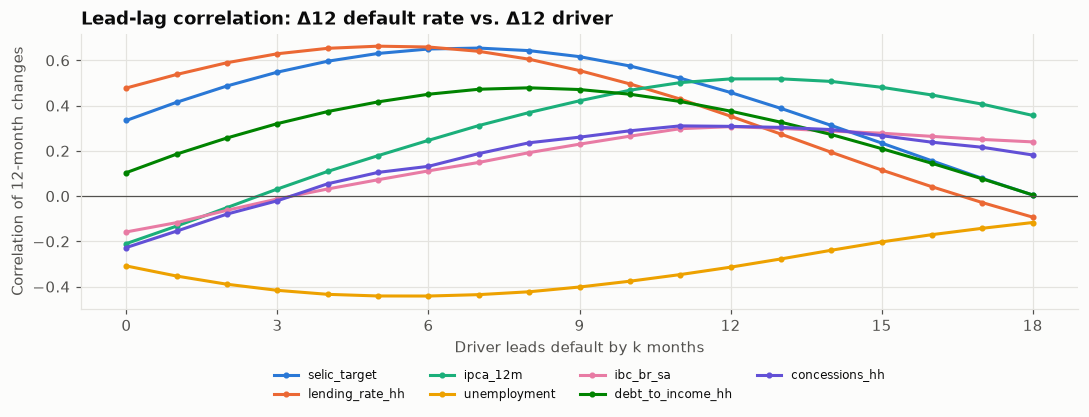

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
for color, c in zip(palette, drivers):
    ax.plot(cc.index, cc[c], color=color, label=c, marker="o", ms=3)
ax.axhline(0, color=plots.INK_2, lw=0.8)
ax.set_xlabel("Driver leads default by k months")
ax.set_ylabel("Correlation of 12-month changes")
ax.set_title("Lead-lag correlation: Δ12 default rate vs. Δ12 driver")
ax.set_xticks(range(0, 19, 3))
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout(); fig.savefig(FIG / "eda_lead_lag.png", dpi=110)

## Takeaways

* **Trend dominates, seasonality is negligible.** STL trend strength is 0.95 vs. seasonal strength 0.07; the average
  seasonal effect is at most ~0.1 p.p. (December). Seasonal-naive is therefore expected to be a weak baseline, and
  the plain naive ("no change") forecast is the bar to beat.
* **The level is non-stationary** (ADF p = 0.40 in levels; 0.07 in first differences), which motivates forecasting
  *changes* in the LightGBM models and letting ETS/ARIMA handle trend/differencing.
* **Monetary policy leads default.** 12-month changes in household lending rates and in the Selic target precede
  12-month changes in the default rate by ~5-7 months (correlation ≈ 0.65); inflation (≈ 13 months) and household
  debt-to-income (≈ 8 months) lead with a weaker link. At a 12-month horizon, today's rate moves are still
  "in the pipeline", which is why lagged drivers are candidate features for the ML model.
* **Unemployment has the "wrong" sign** (≈ -0.44): in 2020-21 unemployment spiked while defaults fell, thanks to
  payment holidays, renegotiations and emergency aid. Relationships are regime-dependent, one more reason to
  evaluate on many rolling origins rather than a single split.
* **The latest data is out-of-sample territory:** August 2026 (6.03%) is the highest reading since the series
  began in 2011, after a tightening cycle that took the Selic target to 15%.